<a href="https://colab.research.google.com/github/JF-74/actividad-2.8-Implementacion-de-Regresion-Lineal/blob/main/Laboratorio_2_8_jose_aravena_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Laboratorio 2.8 - Implementación de Regresión Lineal**




**Licencia** CC BY-NC-SA 4.0

**Base de datos Bloque 1**: https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data


**Licencia** CC BY-NC-SA 4.0

**Base de datos Bloque 2**: https://www.kaggle.com/datasets/javagarm/fifa-19-complete-player-dataset


**Licencia** CC0: Public Domain

**Base de datos Bloque 3**: https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from google.colab import userdata
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from statsmodels.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

In [ ]:
def metricas(y, pred):
    return {"R2": r2_score(y, pred),
            "MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred))}

def vif(X):
    Xc = add_constant(X)
    return pd.DataFrame({"variable": X.columns,
                         "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]
                         }).sort_values("VIF", ascending=False)

Bloque 1: Breast Cancer

In [ ]:
ruta = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print(os.listdir(ruta))

df1 = pd.read_csv(ruta + "/data.csv")
df1.info()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
['data.csv']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null 

In [ ]:
df1 = df1.drop(columns=["id", "Unnamed: 32"])
print(df1.shape)

(569, 31)


**Id** es el identificador del paciente, no una medición por lo cual  su valor es arbitrario y no tiene relacion con las variables a modelar

**Unnamed: 32** tiene una columna vacia (569 de 569 valores nulos), generada por una coma sobrante al final de cada fila del dataset por lo cual no aporta informacion

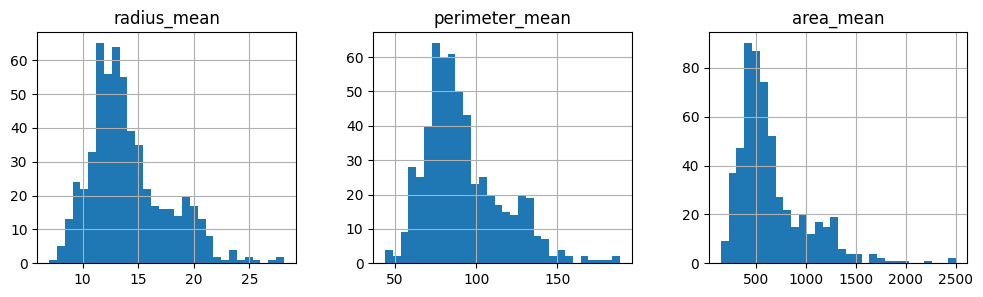

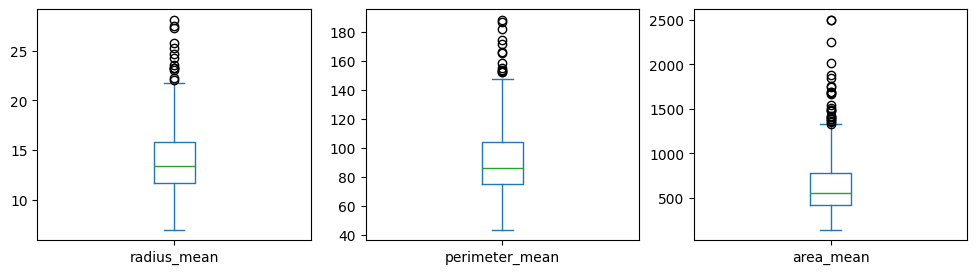

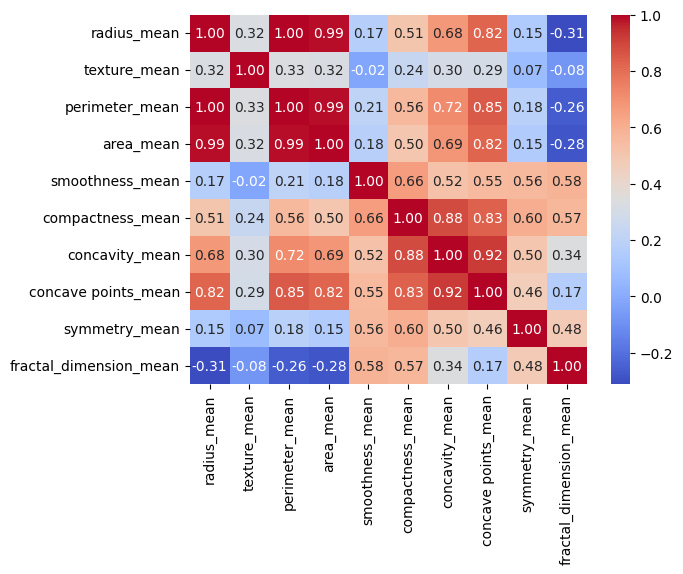

In [ ]:
cols = ["radius_mean", "perimeter_mean", "area_mean"]

df1[cols].hist(bins=30, figsize=(12, 3), layout=(1, 3))
plt.show()

df1[cols].plot(kind="box", subplots=True, figsize=(12, 3))
plt.show()

sns.heatmap(df1.filter(like="_mean").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

**los pequeños** la mayoria de datos se concentran en valores bajos y pocos los casos tienen medidas grandes

**excepcionales** los registros que salen de la norma y son mas grandes que el promedio general

y los 3 (radio,perimetro, area) muestran la misma informacion con 3 nombres distintos

--- perimeter_mean ~ radius_mean ---
Pendiente: 6.863974682090254 | Intercepto: -5.020848584173891
{'R2': 0.9957203798978786, 'MAE': 1.0424218536599767, 'RMSE': np.float64(1.5833892695908438)}


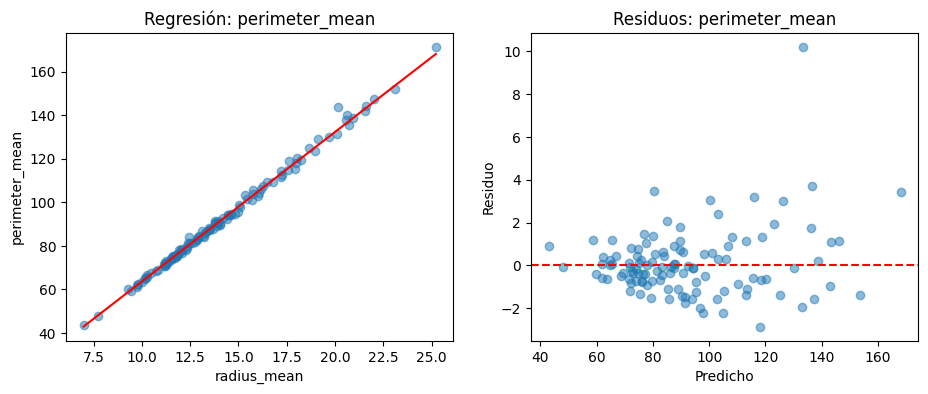

--- area_mean ~ radius_mean ---
Pendiente: 99.04084012256651 | Intercepto: -743.8448648515803
{'R2': 0.9811859948447594, 'MAE': 34.97483865486134, 'RMSE': np.float64(46.57757361337863)}


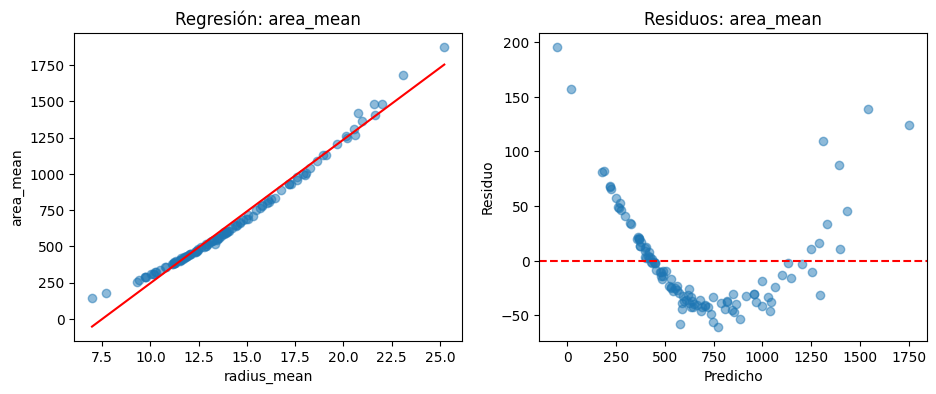

In [ ]:
for objetivo in ["perimeter_mean", "area_mean"]:
    X = df1[["radius_mean"]]
    y = df1[objetivo]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

    modelo = LinearRegression().fit(X_tr, y_tr)
    pred = modelo.predict(X_te)

    print(f"--- {objetivo} ~ radius_mean ---")
    print("Pendiente:", modelo.coef_[0], "| Intercepto:", modelo.intercept_)
    print(metricas(y_te, pred))

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    # Regresión con su línea
    ax[0].scatter(X_te["radius_mean"], y_te, alpha=0.5)
    X_orden = X_te.sort_values("radius_mean")
    ax[0].plot(X_orden["radius_mean"], modelo.predict(X_orden), color="red")
    ax[0].set_title(f"Regresión: {objetivo}")
    ax[0].set_xlabel("radius_mean"); ax[0].set_ylabel(objetivo)
    # Residuos
    ax[1].scatter(pred, y_te - pred, alpha=0.5)
    ax[1].axhline(0, color="red", linestyle="--")
    ax[1].set_title(f"Residuos: {objetivo}")
    ax[1].set_xlabel("Predicho"); ax[1].set_ylabel("Residuo")
    plt.show()

Bloque 2: FIFA 19

In [ ]:
try:
    ruta = kagglehub.dataset_download("karangadiya/fifa19")
    print(os.listdir(ruta))
    df2 = pd.read_csv(ruta + "/data.csv", encoding="latin-1")
except Exception as e:
    print("Descarga desde Kaggle falló, uso el archivo subido a Colab.")
    df2 = pd.read_csv("/content/Fifa19.csv", encoding="latin-1")

print(df2.shape)   # (18207, 89)

Descarga desde Kaggle falló, uso el archivo subido a Colab.
(18207, 89)


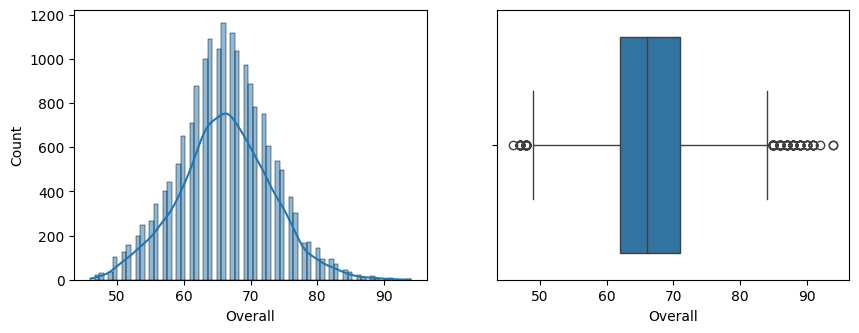

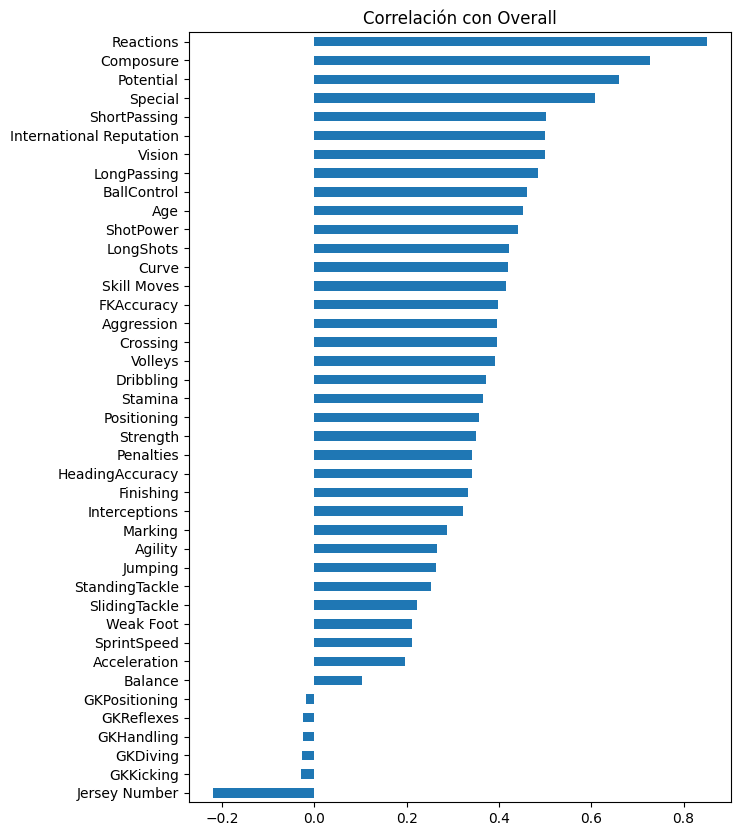

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df2["Overall"], kde=True, ax=ax[0])
sns.boxplot(x=df2["Overall"], ax=ax[1])
plt.show()

num = df2.select_dtypes("number").drop(columns=["Unnamed: 0", "ID"])
corr = num.corr()["Overall"].drop("Overall").sort_values()
corr.plot(kind="barh", figsize=(7, 10), title="Correlación con Overall")
plt.show()

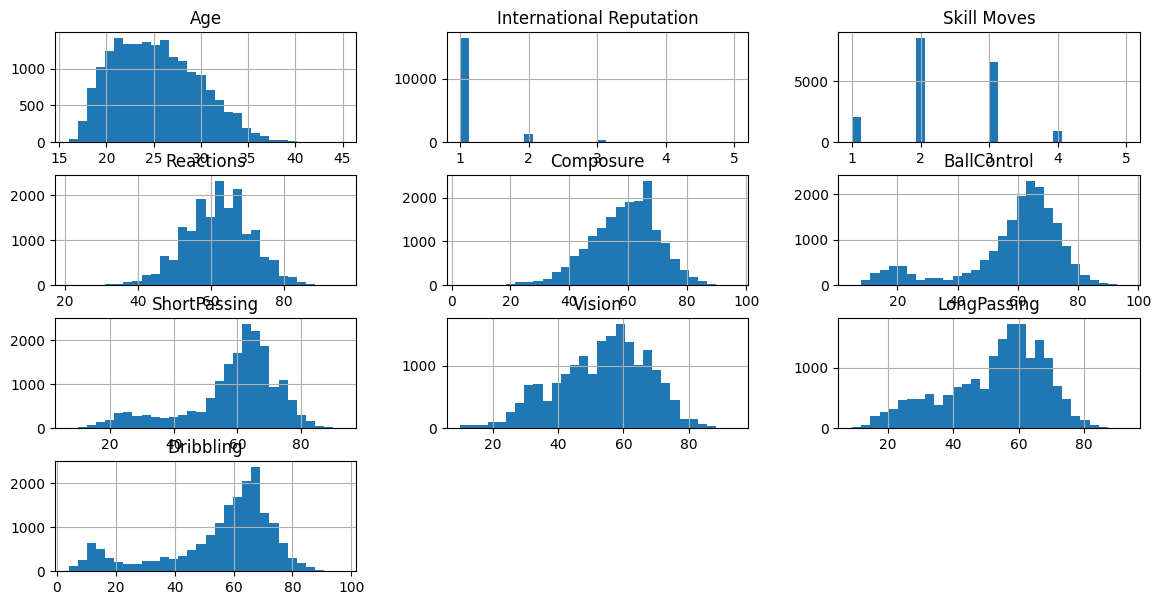

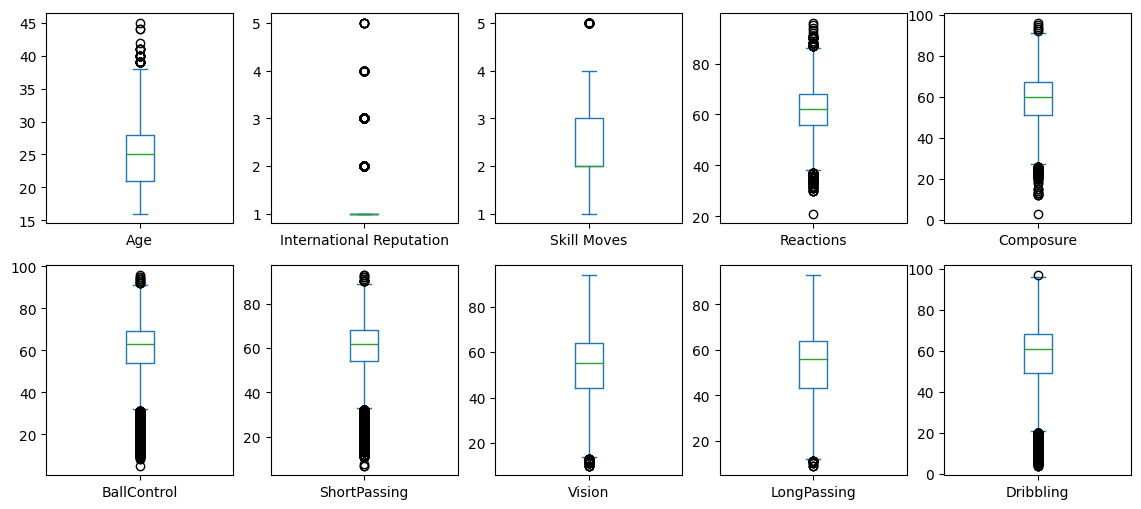

In [ ]:
cands = ["Age", "International Reputation", "Skill Moves", "Reactions", "Composure",
         "BallControl", "ShortPassing", "Vision", "LongPassing", "Dribbling"]

df2[cands].hist(bins=30, figsize=(14, 7))
plt.show()

df2[cands].plot(kind="box", subplots=True, layout=(2, 5), figsize=(14, 6))
plt.show()

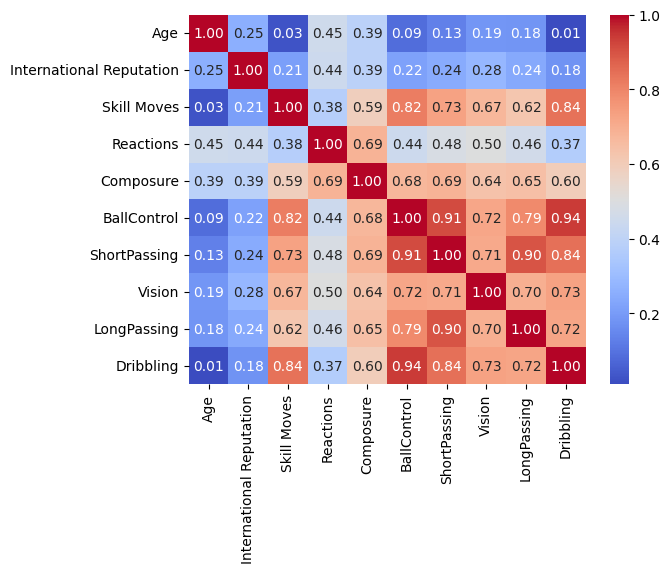

,variable,VIF
5,BallControl,15.622767
6,ShortPassing,11.762270
9,Dribbling,11.078319
8,LongPassing,5.605576
2,Skill Moves,3.663539
4,Composure,3.191122
7,Vision,2.841444
3,Reactions,2.243619
0,Age,1.424033
1,International Reputation,1.282920


In [ ]:
data = df2[cands + ["Overall", "Position"]].dropna()

sns.heatmap(data[cands].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

vif(data[cands])

In [ ]:
eliminar = []   # ej.: ["Dribbling"], decide tú según el VIF
predictores = [c for c in cands if c not in eliminar]
vif(data[predictores])

,variable,VIF
5,BallControl,15.622767
6,ShortPassing,11.762270
9,Dribbling,11.078319
8,LongPassing,5.605576
2,Skill Moves,3.663539
4,Composure,3.191122
7,Vision,2.841444
3,Reactions,2.243619
0,Age,1.424033
1,International Reputation,1.282920


In [ ]:
X = data[predictores]
y = data["Overall"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

modelo2 = LinearRegression().fit(X_tr, y_tr)
pred_tr = modelo2.predict(X_tr)
pred_te = modelo2.predict(X_te)

print(pd.DataFrame({"Entrenamiento": metricas(y_tr, pred_tr),
                    "Prueba": metricas(y_te, pred_te)}).T)
print("\nIntercepto:", modelo2.intercept_)
print(pd.Series(modelo2.coef_, index=predictores).sort_values())

                     R2       MAE      RMSE
Entrenamiento  0.783498  2.531183  3.224635
Prueba         0.775121  2.512536  3.236121

Intercepto: 24.3085323587879
Dribbling                  -0.072962
Vision                     -0.000763
LongPassing                 0.005190
BallControl                 0.021108
ShortPassing                0.028292
Age                         0.071537
Composure                   0.135102
Reactions                   0.462068
Skill Moves                 0.954122
International Reputation    2.066169
dtype: float64


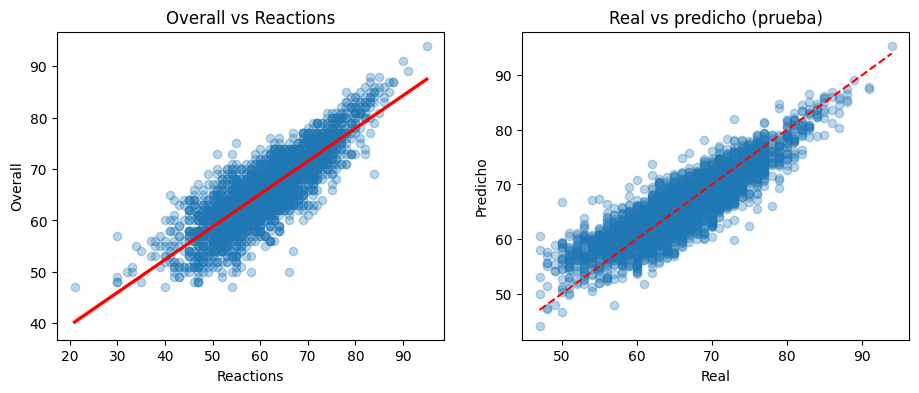

In [ ]:
top = corr[predictores].abs().idxmax()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.regplot(data=data.sample(3000, random_state=42), x=top, y="Overall",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"}, ax=ax[0])
ax[0].set_title(f"Overall vs {top}")

ax[1].scatter(y_te, pred_te, alpha=0.3)
ax[1].plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], "r--")
ax[1].set_xlabel("Real"); ax[1].set_ylabel("Predicho")
ax[1].set_title("Real vs predicho (prueba)")
plt.show()

Arquero | n = 394 | {'R2': 0.712935592865324, 'MAE': 3.111198133178634, 'RMSE': np.float64(3.865170246104579)}
Jugador de campo | n = 3235 | {'R2': 0.7824620234796517, 'MAE': 2.4396231802305905, 'RMSE': np.float64(3.1509403154185516)}


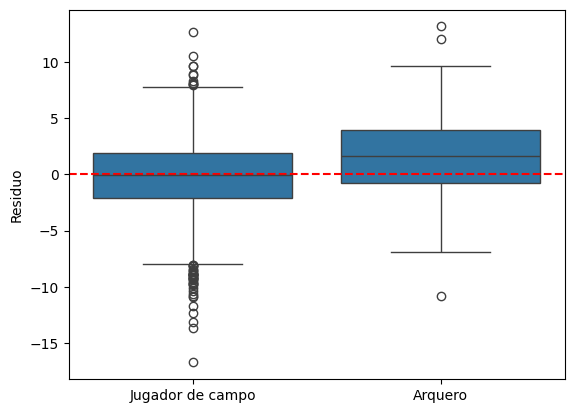

In [ ]:
grupo = np.where(data.loc[X_te.index, "Position"] == "GK", "Arquero", "Jugador de campo")

for g in ["Arquero", "Jugador de campo"]:
    mask = grupo == g
    print(g, "| n =", mask.sum(), "|", metricas(y_te[mask], pred_te[mask]))

sns.boxplot(x=grupo, y=y_te - pred_te)
plt.axhline(0, color="red", linestyle="--")
plt.ylabel("Residuo")
plt.show()

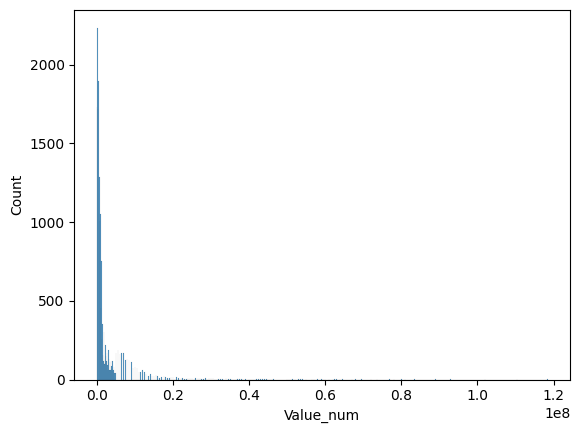

Value_num {'R2': 0.5466912248865339, 'MAE': 1989138.7287880678, 'RMSE': np.float64(4099369.373585741)}
log_Value {'R2': 0.7365399673104865, 'MAE': 0.568617732060488, 'RMSE': np.float64(0.7209688225757799)}


In [ ]:
def a_numero(v):
    v = str(v)
    mult = 1e6 if v.endswith("M") else 1e3 if v.endswith("K") else 1
    n = "".join(c for c in v if c.isdigit() or c == ".")
    return float(n) * mult if n else np.nan

df2["Value_num"] = df2["Value"].map(a_numero)
d = df2[df2["Value_num"] > 0].dropna(subset=predictores)

sns.histplot(d["Value_num"]); plt.show()
d["log_Value"] = np.log1p(d["Value_num"])

for objetivo in ["Value_num", "log_Value"]:
    Xa, Xb, ya, yb = train_test_split(d[predictores], d[objetivo], test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xa, ya)
    print(objetivo, metricas(yb, m.predict(Xb)))

**Bloque 3:** Dataset de student_performance_dataset

In [ ]:
HANDLE = "harshadapatil31/student-performance-and-study-habits-dataset"

try:
    ruta = kagglehub.dataset_download(HANDLE)
    print(os.listdir(ruta))
    df3 = pd.read_csv(ruta + "/student_performance_dataset.csv", keep_default_na=False)
except Exception as e:
    print("Descarga falló, uso el archivo subido a Colab.")
    df3 = pd.read_csv("/content/student_performance_dataset.csv", keep_default_na=False)

print(df3.shape)   # (1000, 12)
df3.info()
display(df3.head())

Using Colab cache for faster access to the 'student-performance-and-study-habits-dataset' dataset.
['student_performance_dataset.csv']
(1000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          1000 non-null   object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  fi

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,None,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [ ]:
df3 = df3.drop(columns=["student_id", "final_grade"])
TARGET = "final_exam_score"
print(df3.shape)

(1000, 10)


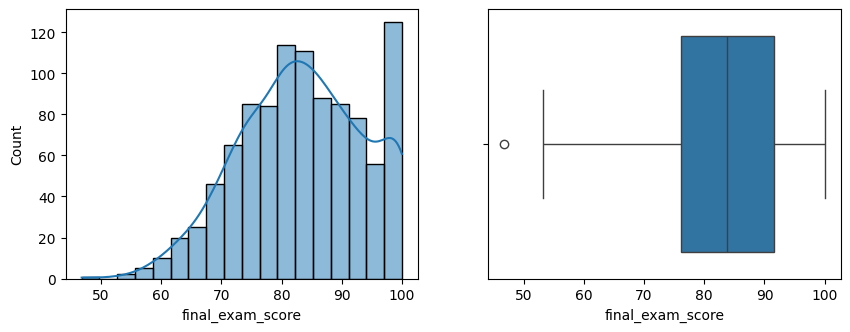

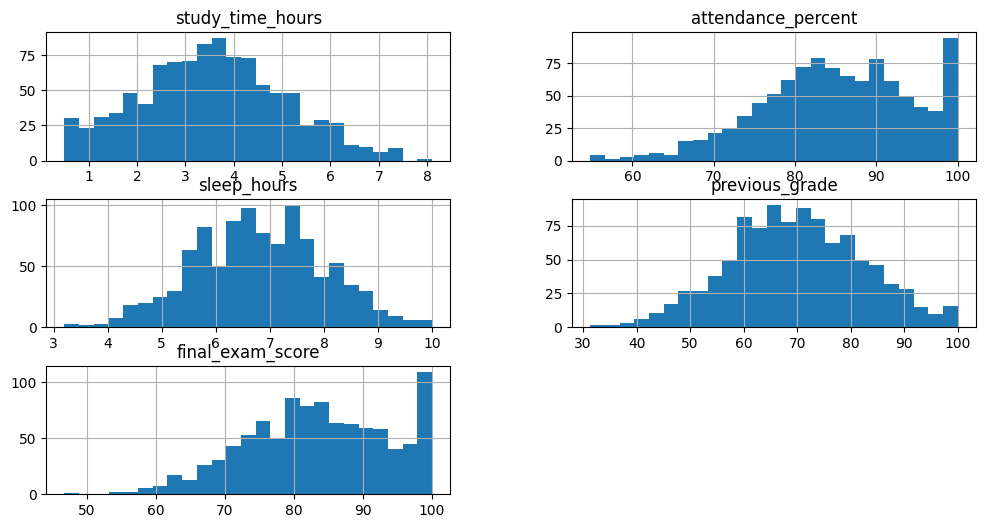

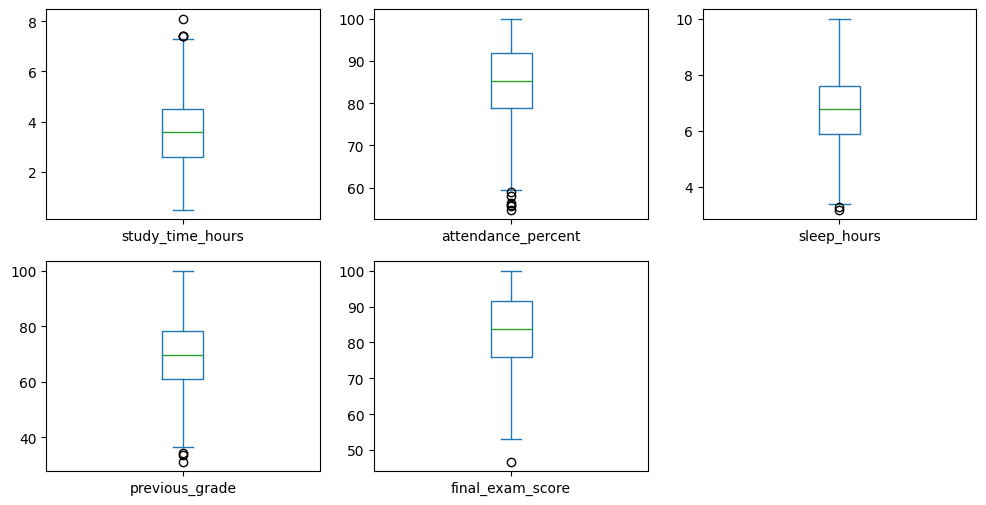

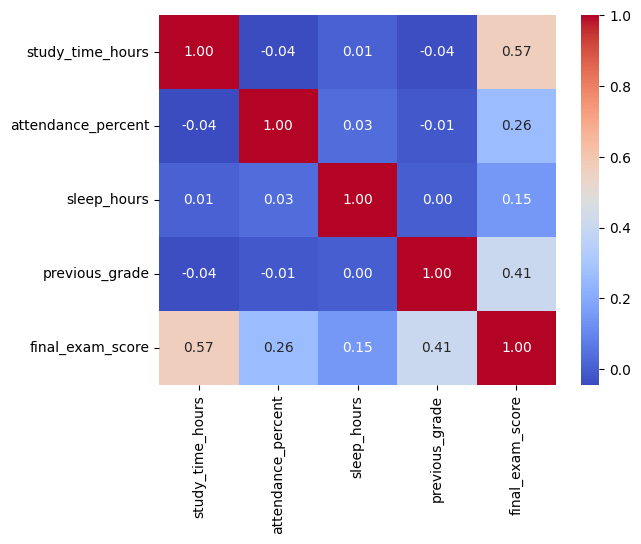

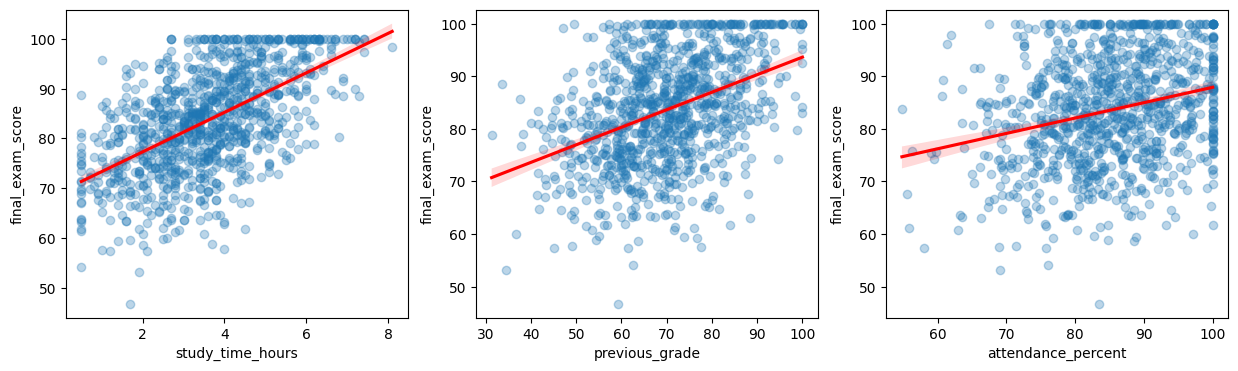

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(df3[TARGET], kde=True, ax=ax[0])
sns.boxplot(x=df3[TARGET], ax=ax[1])
plt.show()

num3 = df3.select_dtypes("number")
num3.hist(bins=25, figsize=(12, 6))
plt.show()
num3.plot(kind="box", subplots=True, layout=(2, 3), figsize=(12, 6))
plt.show()

sns.heatmap(num3.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["study_time_hours", "previous_grade", "attendance_percent"]):
    sns.regplot(data=df3, x=col, y=TARGET, ax=a,
                scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.show()

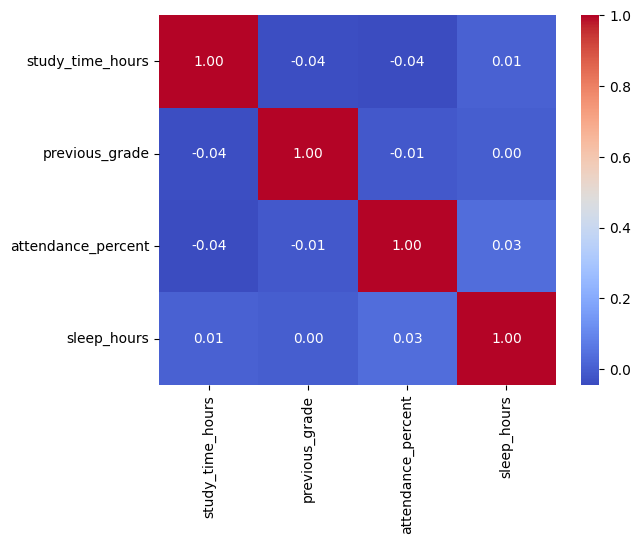

,variable,VIF
2,attendance_percent,1.003354
0,study_time_hours,1.003292
1,previous_grade,1.001532
3,sleep_hours,1.001217


In [ ]:
FEATURES = ["study_time_hours", "previous_grade", "attendance_percent", "sleep_hours"]
data3 = df3[FEATURES + [TARGET, "gender", "part_time_job", "parental_education"]].copy()

sns.heatmap(data3[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()
vif(data3[FEATURES])

                     R2       MAE      RMSE
Entrenamiento  0.604386  5.128632  6.479027
Prueba         0.614618  4.998893  6.440602

Intercepto: 9.784361988501061
study_time_hours      4.137237
previous_grade        0.351122
attendance_percent    0.323908
sleep_hours           1.050491
dtype: float64


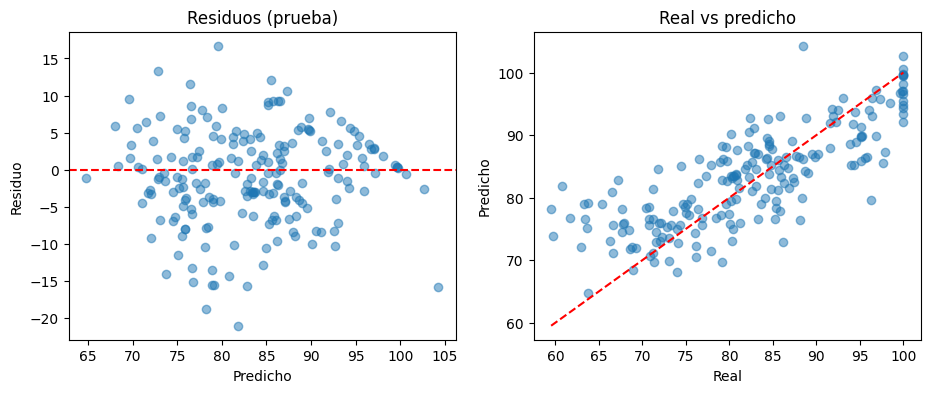

In [ ]:
X = data3[FEATURES]
y = data3[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

modelo3 = LinearRegression().fit(X_tr, y_tr)
p_tr = modelo3.predict(X_tr)
p_te = modelo3.predict(X_te)

print(pd.DataFrame({"Entrenamiento": metricas(y_tr, p_tr),
                    "Prueba": metricas(y_te, p_te)}).T)
print("\nIntercepto:", modelo3.intercept_)
print(pd.Series(modelo3.coef_, index=FEATURES))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(p_te, y_te - p_te, alpha=0.5)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Residuo"); ax[0].set_title("Residuos (prueba)")
ax[1].scatter(y_te, p_te, alpha=0.5)
ax[1].plot([y_te.min(), y_te.max()], [y_te.min(), y_te.max()], "r--")
ax[1].set_xlabel("Real"); ax[1].set_ylabel("Predicho"); ax[1].set_title("Real vs predicho")
plt.show()

--- part_time_job ---
Yes | n = 54 | {'R2': 0.46796411751259004, 'MAE': 5.916489315455711, 'RMSE': np.float64(7.331569158560409)}
No | n = 146 | {'R2': 0.6636992118871194, 'MAE': 4.6595081187662775, 'RMSE': np.float64(6.078068931004003)}


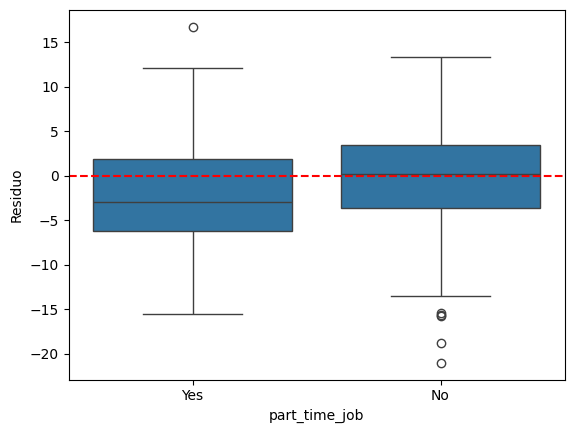

--- gender ---
Male | n = 95 | {'R2': 0.5854977516157602, 'MAE': 5.0518816082792, 'RMSE': np.float64(6.668174581089305)}
Female | n = 105 | {'R2': 0.637978056610963, 'MAE': 4.950951005599628, 'RMSE': np.float64(6.2275402774487505)}


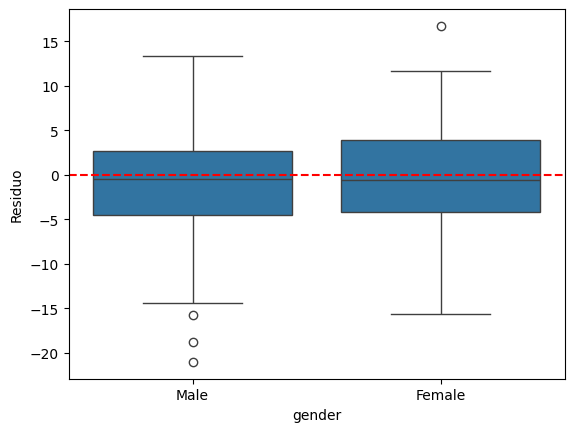

In [ ]:
for seg_col in ["part_time_job", "gender"]:
    seg = data3.loc[X_te.index, seg_col]
    print(f"--- {seg_col} ---")
    for g in seg.unique():
        mask = (seg == g).values
        print(g, "| n =", mask.sum(), "|", metricas(y_te[mask], p_te[mask]))
    sns.boxplot(x=seg, y=y_te - p_te)
    plt.axhline(0, color="red", linestyle="--")
    plt.ylabel("Residuo")
    plt.show()